In [ ]:
import torch
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import time

from datasets import load_dataset
from transformers import (
    AutoTokenizer,
    AutoModelForSequenceClassification
)

from torch import nn
from torch.utils.data import Dataset, DataLoader

from sklearn.metrics import (
    accuracy_score,
    precision_recall_fscore_support,
    classification_report,
    confusion_matrix
)

device = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

print("Using device:", device)

Using device: cuda


In [ ]:
from datasets import load_dataset

dataset = load_dataset(
    "neonwatty/amazon_reviews_multi",
    "en"

)

print(dataset)

README.md:   0%|          | 0.00/4.20k [00:00<?, ?B/s]

en/train-00000-of-00001.parquet: reconstructing file:   0%|          |  0.00B / 29.3MB            

en/train-00000-of-00001.parquet: downloading bytes:           |  0.00B            

en/validation-00000-of-00001.parquet: reconstructing file:   0%|          |  0.00B /  737kB            

en/validation-00000-of-00001.parquet: downloading bytes:           |  0.00B            

en/test-00000-of-00001.parquet: reconstructing file:   0%|          |  0.00B /  727kB            

en/test-00000-of-00001.parquet: downloading bytes:           |  0.00B            

Generating train split:   0%|          | 0/200000 [00:00<?, ? examples/s]

Generating validation split:   0%|          | 0/5000 [00:00<?, ? examples/s]

Generating test split:   0%|          | 0/5000 [00:00<?, ? examples/s]

DatasetDict({
    train: Dataset({
        features: ['review_title', 'review_body', 'review_id', 'stars'],
        num_rows: 200000
    })
    validation: Dataset({
        features: ['review_title', 'review_body', 'review_id', 'stars'],
        num_rows: 5000
    })
    test: Dataset({
        features: ['review_title', 'review_body', 'review_id', 'stars'],
        num_rows: 5000
    })
})


In [ ]:
df = pd.DataFrame(dataset["train"])

print(df.head())

print(df.columns)

                                        review_title  \
0  I'll spend twice the amount of time boxing up ...   
1                                       Not use able   
2                               The product is junk.   
3                             Fucking waste of money   
4                                             bubble   

                                         review_body   review_id  stars  
0  Arrived broken. Manufacturer defect. Two of th...  en_0964290      1  
1  the cabinet dot were all detached from backing...  en_0690095      1  
2  I received my first order of this product and ...  en_0311558      1  
3  This product is a piece of shit. Do not buy. D...  en_0044972      1  
4  went through 3 in one day doesn't fit correct ...  en_0784379      1  
Index(['review_title', 'review_body', 'review_id', 'stars'], dtype='object')


In [ ]:
def convert_sentiment(stars):

    if stars <= 2:
        return 0

    elif stars == 3:
        return 1

    else:
        return 2

In [ ]:
def preprocess(example):

    example["label"] = convert_sentiment(
        example["stars"]
    )

    return example


dataset = dataset.map(preprocess)

Map:   0%|          | 0/200000 [00:00<?, ? examples/s]

Map:   0%|          | 0/5000 [00:00<?, ? examples/s]

Map:   0%|          | 0/5000 [00:00<?, ? examples/s]

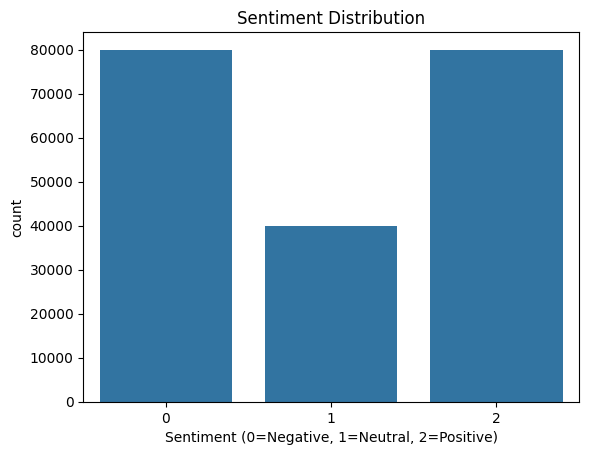

In [ ]:
labels = dataset["train"]["label"]

sns.countplot(x=labels)

plt.title("Sentiment Distribution")
plt.xlabel("Sentiment (0=Negative, 1=Neutral, 2=Positive)")
plt.show()

In [ ]:
train_data = dataset["train"].shuffle(
    seed=42
).select(range(20000))

test_data = dataset["test"].shuffle(
    seed=42
).select(range(5000))

validation_data = dataset["validation"].shuffle(
    seed=42
).select(range(3000))

print("Training:", len(train_data))
print("Validation:", len(validation_data))
print("Testing:", len(test_data))

Training: 20000
Validation: 3000
Testing: 5000


In [ ]:
MODEL_NAME = "bert-base-uncased"

tokenizer = AutoTokenizer.from_pretrained(MODEL_NAME)

MAX_LENGTH = 128

In [ ]:

print(train_data["review_body"][:10])

['3 stars because these are not rear brakes as stated in the item description. At least the mount adapter only worked on the front fork of the bike that I got it for.', 'Does it’s job and it’s gorgeous but mine is falling apart, I had to basically put it together again with hot glue', 'Bought this for handling miscellaneous aircraft parts and hanger "stuff" that I needed to organize; it really fit the bill. The unit arrived quickly, was well packaged and arrived intact (always a good sign). There are five wall mounts-- three on the top and two on the bottom. I wanted to mount it on the wall, so all I had to do was to remove the top two layers of plastic drawers, as well as the bottom corner drawers, place it when I wanted and mark it; I then used some of the new plastic screw in wall anchors (the 50 pound variety) and it easily mounted to the wall. Some have remarked that they wanted dividers for the drawers, and that they made those. Good idea. My application was that I needed somethi

In [ ]:
train_data = train_data.filter(
    lambda x: x["review_body"] is not None
    and len(x["review_body"].strip()) > 0
)

test_data = test_data.filter(
    lambda x: x["review_body"] is not None
    and len(x["review_body"].strip()) > 0
)

print(len(train_data))
print(len(test_data))

Filter:   0%|          | 0/20000 [00:00<?, ? examples/s]

Filter:   0%|          | 0/5000 [00:00<?, ? examples/s]

20000
5000


In [ ]:
train_reviews = list(train_data["review_body"])
test_reviews = list(test_data["review_body"])

In [ ]:
train_tokens = tokenizer(
    train_reviews,
    padding="max_length",
    truncation=True,
    max_length=MAX_LENGTH
)

In [ ]:
test_tokens = tokenizer(
    test_reviews,
    padding="max_length",
    truncation=True,
    max_length=MAX_LENGTH
)

In [ ]:
print(train_tokens["input_ids"][0])
print(train_tokens["attention_mask"][0])

[101, 1017, 3340, 2138, 2122, 2024, 2025, 4373, 13627, 2004, 3090, 1999, 1996, 8875, 6412, 1012, 2012, 2560, 1996, 4057, 15581, 2121, 2069, 2499, 2006, 1996, 2392, 9292, 1997, 1996, 7997, 2008, 1045, 2288, 2009, 2005, 1012, 102, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0]
[1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0]


In [ ]:
import torch

X_train = torch.tensor(train_tokens["input_ids"])
M_train = torch.tensor(train_tokens["attention_mask"])
y_train = torch.tensor(train_data["label"])

X_test = torch.tensor(test_tokens["input_ids"])
M_test = torch.tensor(test_tokens["attention_mask"])
y_test = torch.tensor(test_data["label"])

In [ ]:
print(X_train.shape)
print(y_train.shape)

torch.Size([20000, 128])
torch.Size([20000])


In [ ]:
from torch.utils.data import TensorDataset, DataLoader

train_dataset = TensorDataset(X_train, M_train, y_train)

test_dataset = TensorDataset(X_test, M_test, y_test)

train_loader = DataLoader(
    train_dataset,
    batch_size=16,
    shuffle=True
)

test_loader = DataLoader(
    test_dataset,
    batch_size=16
)

In [ ]:
class LSTMModel(nn.Module):

    def __init__(self):
        super().__init__()

        self.embedding = nn.Embedding(
            30522, 128, padding_idx=0
        )

        self.lstm = nn.LSTM(
            128, 128, batch_first=True
        )

        self.dropout = nn.Dropout(0.3)

        self.fc = nn.Linear(128, 3)

    def forward(self, x, mask):

        x = self.embedding(x)

        lengths = mask.sum(dim=1)

        packed = nn.utils.rnn.pack_padded_sequence(
            x,
            lengths.cpu(),
            batch_first=True,
            enforce_sorted=False
        )

        output, (hidden, cell) = self.lstm(packed)

        output = self.dropout(hidden[-1])

        output = self.fc(output)

        return output

In [ ]:
device = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

lstm_model = LSTMModel().to(device)

print(lstm_model)

LSTMModel(
  (embedding): Embedding(30522, 128, padding_idx=0)
  (lstm): LSTM(128, 128, batch_first=True)
  (dropout): Dropout(p=0.3, inplace=False)
  (fc): Linear(in_features=128, out_features=3, bias=True)
)


In [ ]:
criterion = nn.CrossEntropyLoss()

optimizer = torch.optim.Adam(
    lstm_model.parameters(),
    lr=0.0005
)

In [ ]:
for epoch in range(5):

    lstm_model.train()

    total_loss = 0

    for x, mask, y in train_loader:

        x = x.to(device)
        mask = mask.to(device)
        y = y.to(device)

        optimizer.zero_grad()

        output = lstm_model(x, mask)

        loss = criterion(output, y)

        loss.backward()

        optimizer.step()

        total_loss += loss.item()

    print(
        "Epoch:", epoch + 1,
        "Loss:", total_loss / len(train_loader)
    )

Epoch: 1 Loss: 0.8951891386032105
Epoch: 2 Loss: 0.7333148920297623
Epoch: 3 Loss: 0.6556658929109573
Epoch: 4 Loss: 0.5906031400918961
Epoch: 5 Loss: 0.5271259026646614


In [ ]:
lstm_model.eval()

actual = []
predicted = []

with torch.no_grad():

    for x, mask, y in test_loader:

        x = x.to(device)
        mask = mask.to(device)

        output = lstm_model(x, mask)

        prediction = torch.argmax(output, dim=1)

        actual.extend(y.numpy())
        predicted.extend(prediction.cpu().numpy())

print("LSTM Accuracy:", accuracy_score(actual, predicted))

print(classification_report(
    actual,
    predicted,
    target_names=["Negative", "Neutral", "Positive"]
))

LSTM Accuracy: 0.6878
              precision    recall  f1-score   support

    Negative       0.70      0.82      0.75      2000
     Neutral       0.37      0.26      0.30      1000
    Positive       0.78      0.77      0.78      2000

    accuracy                           0.69      5000
   macro avg       0.62      0.62      0.61      5000
weighted avg       0.67      0.69      0.67      5000



In [ ]:
from transformers import AutoModelForSequenceClassification

bert_model = AutoModelForSequenceClassification.from_pretrained(
    "bert-base-uncased",
    num_labels=3
)

bert_model = bert_model.to(device)

model.safetensors: reconstructing file:   0%|          |  0.00B /  440MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

[transformers] BertForSequenceClassification LOAD REPORT from: bert-base-uncased
Key                                        | Status     | 
-------------------------------------------+------------+-
cls.predictions.transform.LayerNorm.weight | UNEXPECTED | 
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED | 
cls.predictions.transform.dense.weight     | UNEXPECTED | 
cls.seq_relationship.bias                  | UNEXPECTED | 
cls.seq_relationship.weight                | UNEXPECTED | 
cls.predictions.bias                       | UNEXPECTED | 
cls.predictions.transform.dense.bias       | UNEXPECTED | 
classifier.weight                          | MISSING    | 
classifier.bias                            | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


In [ ]:
optimizer = torch.optim.AdamW(
    bert_model.parameters(),
    lr=2e-5
)

In [ ]:
small_train_loader = DataLoader(
    train_dataset,
    batch_size=16,
    shuffle=True
)

small_test_loader = DataLoader(
    test_dataset,
    batch_size=16
)

In [ ]:
small_train_dataset = TensorDataset(
    X_train[:5000],
    M_train[:5000],
    y_train[:5000]
)

small_train_loader = DataLoader(
    small_train_dataset,
    batch_size=16,
    shuffle=True
)

In [ ]:
import time

start = time.time()

bert_model.train()

total_loss = 0

for x, mask, y in small_train_loader:

    x = x.to(device)
    mask = mask.to(device)
    y = y.to(device)

    optimizer.zero_grad()

    output = bert_model(
        input_ids=x,
        attention_mask=mask,
        labels=y
    )

    loss = output.loss
    loss.backward()
    optimizer.step()

    total_loss += loss.item()

print("Training Loss:", total_loss / len(small_train_loader))
print("Training Time:", time.time() - start)

Training Loss: 0.7163074432660977
Training Time: 110.44455647468567


In [ ]:
print(device)

cuda


In [ ]:
print(torch.cuda.get_device_name(0))

Tesla T4


In [ ]:
print(torch.cuda.memory_allocated() / 1024**3, "GB")

1.7031421661376953 GB


In [ ]:
bert_model.eval()

actual_bert = []
predicted_bert = []

with torch.no_grad():

    for x, mask, y in test_loader:

        x = x.to(device)
        mask = mask.to(device)

        output = bert_model(
            input_ids=x,
            attention_mask=mask
        )

        prediction = torch.argmax(
            output.logits,
            dim=1
        )

        actual_bert.extend(y.numpy())
        predicted_bert.extend(prediction.cpu().numpy())

print("BERT Accuracy:",
      accuracy_score(actual_bert, predicted_bert))

print(classification_report(
    actual_bert,
    predicted_bert,
    target_names=["Negative", "Neutral", "Positive"]
))

BERT Accuracy: 0.7342
              precision    recall  f1-score   support

    Negative       0.70      0.92      0.79      2000
     Neutral       0.42      0.19      0.26      1000
    Positive       0.86      0.82      0.84      2000

    accuracy                           0.73      5000
   macro avg       0.66      0.64      0.63      5000
weighted avg       0.71      0.73      0.70      5000



In [ ]:
print("LSTM Accuracy:",
      accuracy_score(actual, predicted))

print("BERT Accuracy:",
      accuracy_score(actual_bert, predicted_bert))

LSTM Accuracy: 0.6878
BERT Accuracy: 0.7342


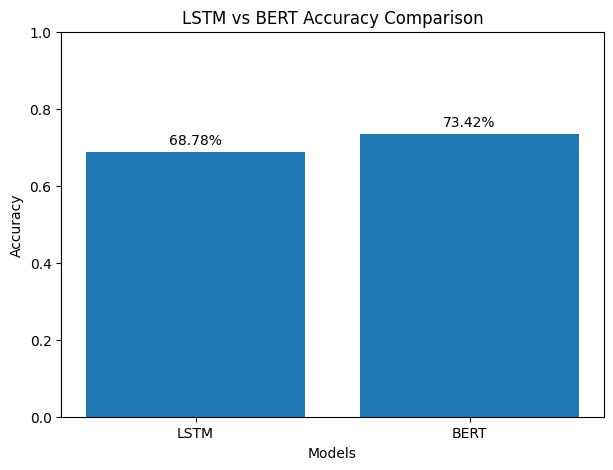

In [ ]:
models = ["LSTM", "BERT"]

accuracies = [
    accuracy_score(actual, predicted),
    accuracy_score(actual_bert, predicted_bert)
]

plt.figure(figsize=(7, 5))
plt.bar(models, accuracies)

plt.title("LSTM vs BERT Accuracy Comparison")
plt.xlabel("Models")
plt.ylabel("Accuracy")
plt.ylim(0, 1)

for i, value in enumerate(accuracies):
    plt.text(i, value + 0.02, f"{value*100:.2f}%", ha="center")

plt.show()

In [ ]:
def predict_sentiment(review):

    inputs = tokenizer(
        review,
        return_tensors="pt",
        truncation=True,
        padding=True,
        max_length=128
    )

    inputs = {
        key: value.to(device)
        for key, value in inputs.items()
    }

    bert_model.eval()

    with torch.no_grad():
        output = bert_model(**inputs)

        prediction = torch.argmax(
            output.logits, dim=1
        ).item()

    labels = ["Negative", "Neutral", "Positive"]

    return labels[prediction]

In [ ]:
print(predict_sentiment(
    "This product is amazing. I absolutely love it!"
))

print(predict_sentiment(
    "Very poor quality. I regret buying this."
))

print(predict_sentiment(
    "The product is average. Nothing special."
))

Positive
Negative
Negative


In [ ]:
bert_model.save_pretrained("amazon_bert_model")
tokenizer.save_pretrained("amazon_bert_model")

print("Model saved successfully!")

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Model saved successfully!
